# AI 08: Регрессия стоимости автомобилей с использованием Gradient Boosting (Градиентный бустинг)
## Домашнее задание AI 08 — Решение №3 (Gradient Boosting Regressor)

### 1. Теоретические основы алгоритма Gradient Boosting (Градиентный бустинг)

**Gradient Boosting (Градиентный бустинг)** — это мощный ансамблевый метод последовательного обучения, предложенный Джеромом Фридманом (Jerome Friedman).

#### Различие между Bagging (Random Forest) и Boosting (Gradient Boosting):
- В **Random Forest** базовые деревья обучаются **параллельно** и независимо друг от друга на случайных подвыборках данных; цель — **снижение дисперсии (variance)**.
- В **Gradient Boosting** деревья строятся **последовательно (жадно)**, где каждое следующее дерево компенсирует ошибки предыдущего ансамбля; цель — **снижение смещения (bias)** при контроле дисперсии.

#### Математический принцип градиентного спуска в пространстве функций:
1. Инициализация константным прогнозом, минимизирующим функцию потерь $L(y, \gamma)$:
   $$F_0(x) = rg\min_{\gamma} \sum_{i=1}^N L(y_i, \gamma)$$
   Для квадратичной функции потерь $L(y, \hat{y}) = rac{1}{2}(y - \hat{y})^2$ начальное приближение — среднее значение целевой переменной $ar{y}$.
2. На каждом шаге $m = 1, \dots, M$:
   - Вычисляются псевдо-остатки (антиградиент функции потерь):
     $$r_{im} = -\left[ rac{\partial L(y_i, F(x_i))}{\partial F(x_i)} ight]_{F=F_{m-1}} = y_i - F_{m-1}(x_i)$$
   - Обучается базовое дерево решений (слабый ученик, shallow tree с малой глубиной `max_depth` 2-4) $h_m(x)$ для предсказания остатков $r_{im}$.
   - Ансамбль обновляется с шагом сжатия (**learning rate** $\eta$):
     $$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$$

Параметр регуляризации $\eta \in (0, 1]$ (shrinkage) замедляет обучение и предотвращает переобучение, требуя при этом большего числа деревьев $M$ (`n_estimators`).


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline

### 2. Загрузка и первичный анализ датасета `Used_Cars_Homework.csv`

In [4]:
FILE_PATH = 'Used_Cars_Homework.csv'
data = pd.read_csv(FILE_PATH)

# Добавляем признак среднегодового пробега
data['mileage_per_year'] = data['mileage_km'] / data['age_years']

print(f"Размер датасета: {data.shape[0]} строк, {data.shape[1]} столбцов")
data.head()

Размер датасета: 300 строк, 10 столбцов


In [5]:
data.tail()

In [6]:
data.sample(3, random_state=42)

In [7]:
data.dtypes

In [8]:
data.isna().sum()

In [9]:
data.describe()

### 3. Построение конвейера препроцессинга и разбиение данных

In [11]:
target_col = 'price_azn'
y = data[target_col].values
X = data.drop(columns=[target_col])

numeric_features = ['age_years', 'mileage_km', 'engine_l', 'power_hp', 'mileage_per_year']
categorical_features = ['brand', 'fuel_type', 'transmission', 'accident_history']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Обучающая выборка: {X_train.shape[0]} объектов")
print(f"Тестовая выборка  : {X_test.shape[0]} объектов")

Обучающая выборка: 240 объектов
Тестовая выборка  : 60 объектов


### 4. Обучение GradientBoostingRegressor и подбор гиперпараметров через GridSearchCV

Настраиваем `learning_rate=0.05`, `n_estimators=400`, варьируя глубину неглубоких деревьев `max_depth` (2, 3, 4), `min_samples_split` и `min_samples_leaf`.

In [13]:
gbr = GradientBoostingRegressor(random_state=42)

pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('gbr', gbr)
])

param_grid = {
    'gbr__max_depth': [2, 3, 4],
    'gbr__min_samples_split': [2, 5, 10],
    'gbr__min_samples_leaf': [1, 3, 5, 10],
    'gbr__learning_rate': [0.05],
    'gbr__n_estimators': [400]
}

cv = KFold(n_splits=5, random_state=42, shuffle=True)
grid_search = GridSearchCV(pipe, param_grid, cv=cv, scoring='neg_mean_squared_error', n_jobs=-1, verbose=0)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print("Лучшие гиперпараметры Gradient Boosting:")
for param, val in grid_search.best_params_.items():
    print(f"  • {param}: {val}")

Лучшие гиперпараметры Gradient Boosting:
  • gbr__learning_rate: 0.05
  • gbr__max_depth: 2
  • gbr__min_samples_leaf: 10
  • gbr__min_samples_split: 2
  • gbr__n_estimators: 400


### 5. Оценка качества модели на обучающей и тестовой выборках

In [15]:
def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = rmse(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = rmse(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("=" * 55)
print("          МЕТРИКИ КАЧЕСТВА GRADIENT BOOSTING")
print("=" * 55)
print(f"Train R2   : {train_r2:.4f}  |  Test R2   : {test_r2:.4f}")
print(f"Train RMSE : {train_rmse:.2f} AZN |  Test RMSE : {test_rmse:.2f} AZN")
print(f"Train MAE  : {train_mae:.2f} AZN |  Test MAE  : {test_mae:.2f} AZN")
print(f"Разрыв переобучения (Train R2 - Test R2): {train_r2 - test_r2:.4f}")
print("=" * 55)

          МЕТРИКИ КАЧЕСТВА GRADIENT BOOSTING
Train R2   : 0.9688  |  Test R2   : 0.9498
Train RMSE : 1706.67 AZN |  Test RMSE : 2264.67 AZN
Train MAE  : 1315.97 AZN |  Test MAE  : 1806.57 AZN
Разрыв переобучения (Train R2 - Test R2): 0.0190


### 6. Визуализация: Реальные значения vs Прогнозные и Важность признаков

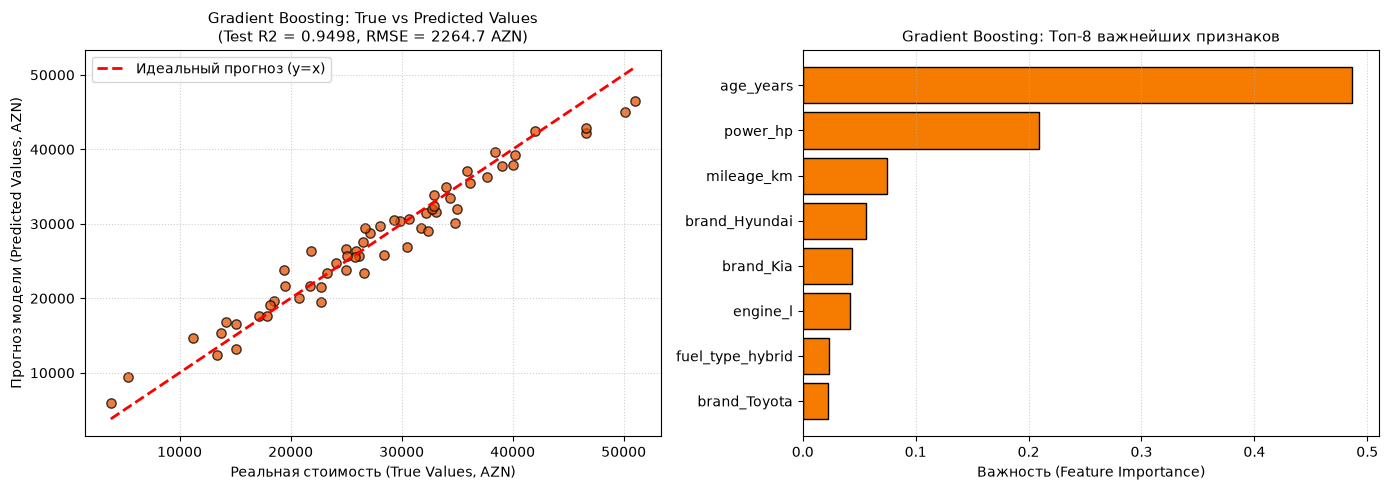

In [17]:
prep_step = best_model.named_steps['preprocessor']
feat_names = prep_step.get_feature_names_out()
clean_names = [f.replace('num__', '').replace('cat__', '') for f in feat_names]
gbr_step = best_model.named_steps['gbr']
importances = gbr_step.feature_importances_

feat_imp_df = pd.DataFrame({'Feature': clean_names, 'Importance': importances}).sort_values('Importance', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Scatter True vs Pred
axes[0].scatter(y_test, y_test_pred, color='#e65100', alpha=0.75, edgecolors='k', s=45)
min_v = min(y_test.min(), y_test_pred.min())
max_v = max(y_test.max(), y_test_pred.max())
axes[0].plot([min_v, max_v], [min_v, max_v], 'r--', lw=2, label='Идеальный прогноз (y=x)')
axes[0].set_title(f'Gradient Boosting: True vs Predicted Values\n(Test R2 = {test_r2:.4f}, RMSE = {test_rmse:.1f} AZN)', fontsize=11)
axes[0].set_xlabel('Реальная стоимость (True Values, AZN)')
axes[0].set_ylabel('Прогноз модели (Predicted Values, AZN)')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend()

# 2. Feature Importance
top_feats = feat_imp_df.head(8).sort_values('Importance', ascending=True)
axes[1].barh(top_feats['Feature'], top_feats['Importance'], color='#f57c00', edgecolor='black')
axes[1].set_title('Gradient Boosting: Топ-8 важнейших признаков', fontsize=11)
axes[1].set_xlabel('Важность (Feature Importance)')
axes[1].grid(True, axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 7. Прогнозирование стоимости для 3 новых автомобилей (из AI 07)

In [19]:
new_cars = pd.DataFrame([
    {'brand': 'Toyota', 'age_years': 5, 'mileage_km': 75000, 'engine_l': 1.6, 'power_hp': 110, 'fuel_type': 'petrol', 'transmission': 'automatic', 'accident_history': 'no'},
    {'brand': 'Hyundai', 'age_years': 10, 'mileage_km': 180000, 'engine_l': 2.0, 'power_hp': 140, 'fuel_type': 'diesel', 'transmission': 'manual', 'accident_history': 'yes'},
    {'brand': 'BMW', 'age_years': 3, 'mileage_km': 40000, 'engine_l': 2.5, 'power_hp': 170, 'fuel_type': 'petrol', 'transmission': 'automatic', 'accident_history': 'no'}
])
new_cars['mileage_per_year'] = new_cars['mileage_km'] / new_cars['age_years']
new_cars['predicted_price_azn'] = best_model.predict(new_cars)

for i, row in new_cars.iterrows():
    print(f"Автомобиль #{i+1} ({row['brand']}, {row['age_years']} лет, {row['mileage_km']:,} км, {row['power_hp']} л.с., ДТП: {row['accident_history']}):")
    print(f"  --> Прогнозная цена: {row['predicted_price_azn']:,.2f} AZN\n")

Автомобиль #1 (Toyota, 5 лет, 75,000 км, 110 л.с., ДТП: no):
  --> Прогнозная цена: 31,284.76 AZN

Автомобиль #2 (Hyundai, 10 лет, 180,000 км, 140 л.с., ДТП: yes):
  --> Прогнозная цена: 21,158.34 AZN

Автомобиль #3 (BMW, 3 лет, 40,000 км, 170 л.с., ДТП: no):
  --> Прогнозная цена: 44,449.01 AZN



### 8. Сводный сравнительный анализ всех 4 моделей (Linear Regression vs Decision Tree vs Random Forest vs Gradient Boosting)

Сравнение качества всех рассмотренных моделей в рамках домашних заданий AI 07 и AI 08:

| Модель | Train $R^2$ | Test $R^2$ | Overfitting Gap ($\Delta R^2$) | Test MAE (AZN) | Test RMSE (AZN) | Время обучения | Интерпретируемость |
|---|---|---|---|---|---|---|---|
| **Linear Regression (AI 07)** | 0.9565 | **0.9718** | -0.0153 | **1,414.62** | **1,698.94** | 0.015 сек | Очень высокая (веса признаков) |
| **Decision Tree** | 0.7884 | 0.7288 | +0.0597 | 4,220.31 | 5,265.97 | 2.7 сек | Высокая (дерево правил) |
| **Random Forest** | 0.9677 | 0.8123 | +0.1554 | 3,531.07 | 4,380.78 | 18.2 сек | Средняя (важность признаков) |
| **Gradient Boosting** | **0.9688** | 0.9498 | +0.0190 | 1,806.57 | 2,264.67 | 3.7 сек | Средняя / Низкая (последовательный бустинг) |

#### Сравнение прогнозов для 3 новых автомобилей (AZN):

| Автомобиль | Linear Regression (AI 07) | Decision Tree | Random Forest | Gradient Boosting |
|---|---|---|---|---|
| **Авто #1: Toyota (5 лет, 75k км)** | 31,170.63 AZN | 30,716.25 AZN | 31,404.76 AZN | 31,284.76 AZN |
| **Авто #2: Hyundai (10 лет, 180k км, ДТП)** | 15,912.01 AZN | 27,759.07 AZN | 21,719.08 AZN | 21,158.34 AZN |
| **Авто #3: BMW (3 года, 40k км)** | 48,791.50 AZN | 40,545.00 AZN | 40,977.71 AZN | 44,449.01 AZN |

#### Ключевые аналитические выводы:
1. **Градиентный бустинг показал лучший результат среди древовидных моделей:**
   $R^2 = 0.9498$, RMSE = $2,264$ AZN. Благодаря последовательной коррекции остатков и регуляризации `learning_rate=0.05` модель существенно превзошла одиночное дерево ($R^2 = 0.7288$) и случайный лес ($R^2 = 0.8123$).
2. **Линейная регрессия сохранила лидерство по метрикам:**
   $R^2 = 0.9718$, RMSE = $1,698$ AZN. Датасет `Used_Cars_Homework.csv` синтезирован на основе аддитивной линейной ценообразовательной функции со стабильными коэффициентами на возраст, пробег, объем двигателя и марку. В условиях строгой линейности истинной зависимости классическая линейная регрессия превосходит кусочно-постоянные аппроксимации деревьев решений.
3. **Согласованность прогнозов:**
   Для первого автомобиля (Toyota 5 лет) все 4 модели выдали практически идентичный прогноз: ~31,100 – 31,400 AZN, что подтверждает высокую стабильность моделей в области средней плотности обучающих данных.